# Random Forest: phishing email detection

**Topic:** Random Forest (Yevheniia's part) / AdaBoost (Era's part)

| Structure | Where |
|---|---|
| Pure Python implementation | Sections 3–4: bootstrap sampling, random features, voting, OOB score and feature importance, all written by hand |
| Comparison with sklearn | Section 6: accuracy, probabilities, feature importances, speed |
| Hyperparameter analysis | Section 7: the lecture's three Random Forest parameters (number of trees, sample size, feature subset size), plus `max_depth` |


## 1. Imports

In [ ]:
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# sklearn: used for the base decision tree, for the comparison and for metrics only
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

np.set_printoptions(precision=3, suppress=True) # to print numbers with 3 decimals 0.777
plt.rcParams["figure.dpi"] = 110 # for the sharp and large pictures

## 2. Data: phishing emails

Each email is described by 3 features:

| feature | meaning |
|---|---|
| `num_links` | number of links in the email (0–9) |
| `urgent_words` | 1 if the email contains urgent words |
| `sender_known` | 1 if the sender is known |

Label: **+1 = phishing**, **−1 = legit**. I use ±1 rather than 0/1 because AdaBoost (Era's part) needs ±1 labels, so both notebooks share the same data.

### 2.1 Toy data (10 emails)

In [ ]:
X_toy = np.array([
    [6, 1, 0],
    [4, 1, 0],
    [8, 0, 0],
    [5, 0, 1],
    [1, 1, 1],
    [0, 0, 1],
    [2, 0, 1],
    [3, 1, 1],
    [1, 0, 0],
    [2, 0, 1],
])
y_toy = np.array([1, 1, 1, 1, 1, -1, -1, -1, -1, -1])
features = ["num_links", "urgent_words", "sender_known"]
class_names = {-1: "legit", 1: "phishing"}

toy_df = pd.DataFrame(X_toy, columns=features)
toy_df["label"] = [class_names[v] for v in y_toy]
toy_df

,num_links,urgent_words,sender_known,label
0,6,1,0,phishing
1,4,1,0,phishing
2,8,0,0,phishing
3,5,0,1,phishing
4,1,1,1,phishing
5,0,0,1,legit
6,2,0,1,legit
7,3,1,1,legit
8,1,0,0,legit
9,2,0,1,legit


### 2.2 More emails (300 in total)

We generate 290 more emails from a hidden "true" rule plus noise:

$$score = 0.5\cdot num\_links + 1.5\cdot urgent - 2\cdot known + \varepsilon,\qquad \varepsilon\sim\mathcal N(0,\,1.5^2)$$

An email is phishing if `score > 2`. The noise term means even a perfect model **cannot reach 100 %**: some emails look phishy but are legit, and the other way round.

In [ ]:
rng = np.random.default_rng(0)
n = 290
num_links = rng.integers(0, 10, n)
urgent = rng.integers(0, 2, n)
known = rng.integers(0, 2, n)
score = 0.5 * num_links + 1.5 * urgent - 2 * known + rng.normal(0, 1.5, n)
y_new = np.where(score > 2, 1, -1)

X = np.vstack([X_toy, np.column_stack([num_links, urgent, known])])
y = np.concatenate([y_toy, y_new])
print(X.shape, "phishing:", (y == 1).sum(), "legit:", (y == -1).sum())

(300, 3) phishing: 163 legit: 137


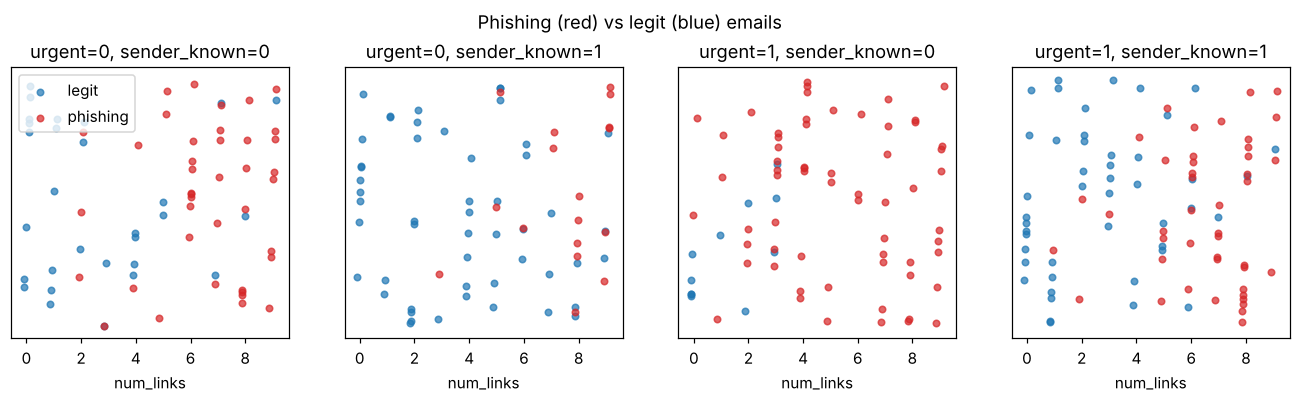

In [ ]:
# How do the classes look? One panel per (urgent, known) combination,
# x-axis = number of links, small vertical jitter so points do not overlap.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
jitter = np.random.default_rng(1).uniform(-0.3, 0.3, len(X))
for ax, (u, k) in zip(axes, [(0, 0), (0, 1), (1, 0), (1, 1)]):
    m = (X[:, 1] == u) & (X[:, 2] == k)
    for label, color in [(-1, "tab:blue"), (1, "tab:red")]:
        mm = m & (y == label)
        ax.scatter(X[mm, 0] + jitter[mm] * 0.5, jitter[mm], c=color, s=18,
                   alpha=0.7, label=class_names[label])
    ax.set_title(f"urgent={u}, sender_known={k}")
    ax.set_xlabel("num_links"); ax.set_yticks([])
axes[0].legend(loc="upper left")
plt.suptitle("Phishing (red) vs legit (blue) emails", y=1.04)
plt.show()

**What we see:** more links and urgent words push towards phishing, and a known sender pushes towards legit. The classes overlap, which is the noise. That overlap is why a single deep tree overfits and why averaging many trees helps.

Train/test split (70 / 30, stratified so both parts have the same class ratio):

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape)

# Reference point: accuracy of the TRUE noise-free rule on the test set.
# No model should be expected to do much better than this.
true_rule = np.where(0.5 * X_test[:, 0] + 1.5 * X_test[:, 1] - 2 * X_test[:, 2] > 2, 1, -1)
print("accuracy of the true (noise-free) rule on test:", round(np.mean(true_rule == y_test), 3))

train: (210, 3)  test: (90, 3)
accuracy of the true (noise-free) rule on test: 0.822


## 3. How a Random Forest works (on the toy data)

**Problem with one decision tree:** a deep tree memorises the training data. If you change a few emails, you get a very different tree. The tree has **high variance**.

**Idea:** train many *different* trees and let them vote. Averaging many noisy but independent opinions cancels the noise.

How do I make the trees different when I only have one dataset? Two sources of randomness:

1. **Bagging (bootstrap aggregating):** each tree gets its own *bootstrap sample*: $n$ rows drawn **with replacement** from the $n$ training rows.
2. **Random feature selection:** at every split, the tree may only look at a random subset of `max_features` features. Otherwise every tree would start with the same strongest feature, and the trees would be too similar.

**Prediction:** every tree votes and the majority wins (or I average the trees' probabilities; see "soft voting" below).

$$\hat y(x) = \text{majority}\{\,h_1(x),\,h_2(x),\,\dots,\,h_T(x)\,\}$$

### 3.1 Bootstrap sample

In [ ]:
def bootstrap_sample(X, y, rng):
    # Draw n row indices WITH replacement -> some rows repeat, some are left out
    n = len(X)
    idx = rng.integers(0, n, size=n)
    return X[idx], y[idx], idx

rng = np.random.default_rng(42)
Xb, yb, idx = bootstrap_sample(X_toy, y_toy, rng)

print("chosen row indices :", np.sort(idx))
print("times each row used:", np.bincount(idx, minlength=len(X_toy)))
print("out-of-bag rows    :", np.setdiff1d(np.arange(len(X_toy)), idx))

chosen row indices : [0 0 0 2 4 4 6 6 7 8]
times each row used: [3 0 1 0 2 0 2 1 1 0]
out-of-bag rows    : [1 3 5 9]


Each row is **not** picked in a single draw with probability $1-\frac1n$. Over $n$ draws:

$$P(\text{row never chosen}) = \left(1-\tfrac1n\right)^n \xrightarrow{n\to\infty} e^{-1}\approx 0.368$$

So each tree sees about **63.2 %** of the distinct rows. The other ~36.8 % are its **out-of-bag (OOB)** rows. That tree never saw them, so I can use them as a free validation set. Quick check:

In [ ]:
n = 300
unique_fraction = [len(np.unique(rng.integers(0, n, n))) / n for _ in range(2000)]
print("simulated fraction of unique rows:", round(np.mean(unique_fraction), 4))
print("theory 1 - (1 - 1/n)^n          :", round(1 - (1 - 1 / n) ** n, 4))

simulated fraction of unique rows: 0.6325
theory 1 - (1 - 1/n)^n          : 0.6327


### 3.2 One tree on one bootstrap sample

In [ ]:
# max_features="sqrt": at each split the tree considers only sqrt(3) -> 1 random feature
tree = DecisionTreeClassifier(max_features="sqrt", random_state=0)
tree.fit(Xb, yb)

new_email = np.array([[4, 0, 1]])   # 4 links, no urgent words, known sender
print("this tree says:", class_names[tree.predict(new_email)[0]])

this tree says: legit


### 3.3 Many trees, then a vote

In [ ]:
n_trees = 7
trees = []
for i in range(n_trees):
    Xb, yb, _ = bootstrap_sample(X_toy, y_toy, rng)                   # 1. own bootstrap sample
    t = DecisionTreeClassifier(max_features="sqrt",                    # 2. random features per split
                               random_state=int(rng.integers(2**31 - 1)))
    t.fit(Xb, yb)
    trees.append(t)

votes = [t.predict(new_email)[0] for t in trees]                        # 3. every tree votes
print("votes:", [class_names[v] for v in votes])
print("count:", Counter(votes))
winner = Counter(votes).most_common(1)[0][0]                            # 4. majority wins
print("forest says:", class_names[winner])

votes: ['legit', 'legit', 'legit', 'legit', 'phishing', 'phishing', 'phishing']
count: Counter({np.int64(-1): 4, np.int64(1): 3})
forest says: legit


The individual trees **disagree**; that diversity is what I want. The vote is more stable than any single tree.

**Hard vs soft voting:**
* *hard voting:* each tree gives one vote (a class) and I count the votes.
* *soft voting:* each tree gives probabilities (the class fractions in its leaf) and I **average** them. sklearn's `RandomForestClassifier` uses soft voting. Our implementation supports both.

## 4. Putting it all together: `RandomForestScratch`

Same interface as sklearn: `fit`, `predict_proba`, `predict`, `score`, plus `oob_score_` and `feature_importances_`.

**Detail to watch:** a bootstrap sample can, by chance, contain **only one class**. That tree's `predict_proba` then returns a single column. `_tree_proba` places each tree's columns at the right position of the forest's class list, so the averaging never mixes up the classes.

In [ ]:
class RandomForestScratch:
    """Random Forest classifier written from scratch.

    Only the base learner (one decision tree) comes from sklearn.
    Bootstrap sampling, feature randomness, voting, OOB score and
    feature importance are implemented here.

    Parameters
    ----------
    n_estimators : number of trees
    max_features : features considered at each split ("sqrt", int, or None = all)
    max_depth, min_samples_leaf : passed to each tree (controls tree size)
    max_samples : size of each bootstrap sample as a fraction of n (None = n, the classic choice)
    bootstrap : if False every tree sees the full training set
    voting : "soft" = average probabilities (like sklearn), "hard" = majority vote
    random_state : seed for reproducibility
    """

    def __init__(self, n_estimators=100, max_features="sqrt", max_depth=None,
                 min_samples_leaf=1, max_samples=None, bootstrap=True, voting="soft",
                 random_state=None):
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_samples = max_samples
        self.bootstrap = bootstrap
        self.voting = voting
        self.random_state = random_state

    # ------------------------------------------------------------ training
    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        n_samples = len(X)
        self.classes_ = np.unique(y)
        rng = np.random.default_rng(self.random_state)
        # sample size per tree (lecture: "sample size" parameter)
        m = n_samples if self.max_samples is None else max(1, round(self.max_samples * n_samples))

        self.trees_ = []
        self.oob_masks_ = []
        for _ in range(self.n_estimators):
            # 1) bootstrap sample (or full data if bootstrap=False)
            if self.bootstrap:
                idx = rng.integers(0, n_samples, size=m)
            else:
                idx = np.arange(n_samples)

            # 2) a tree that looks at a random feature subset at every split
            tree = DecisionTreeClassifier(
                max_features=self.max_features,
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                random_state=int(rng.integers(2**31 - 1)),
            )
            tree.fit(X[idx], y[idx])

            # 3) remember which rows this tree did NOT see (out-of-bag)
            oob = np.ones(n_samples, dtype=bool)
            oob[idx] = False

            self.trees_.append(tree)
            self.oob_masks_.append(oob)

        if self.bootstrap:
            self.oob_score_ = self._oob_score(X, y)
        return self

    # ------------------------------------------------------------ prediction
    def _tree_proba(self, tree, X):
        """Probabilities of one tree, aligned to the forest's class order."""
        proba = np.zeros((len(X), len(self.classes_)))
        cols = np.searchsorted(self.classes_, tree.classes_)
        proba[:, cols] = tree.predict_proba(X)
        return proba

    def predict_proba(self, X):
        X = np.asarray(X)
        if self.voting == "soft":
            # average the probability estimates of all trees
            return np.mean([self._tree_proba(t, X) for t in self.trees_], axis=0)
        # hard voting: fraction of trees that voted for each class
        votes = np.array([t.predict(X) for t in self.trees_])        # (n_trees, n_samples)
        return np.stack([(votes == c).mean(axis=0) for c in self.classes_], axis=1)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

    # ------------------------------------------------------------ extras
    def _oob_score(self, X, y):
        """Each training row is predicted ONLY by trees that did not see it."""
        proba_sum = np.zeros((len(X), len(self.classes_)))
        for tree, oob in zip(self.trees_, self.oob_masks_):
            if oob.any():
                proba_sum[oob] += self._tree_proba(tree, X[oob])
        has_oob = proba_sum.sum(axis=1) > 0          # rows that were OOB at least once
        pred = self.classes_[np.argmax(proba_sum[has_oob], axis=1)]
        return np.mean(pred == y[has_oob])

    @property
    def feature_importances_(self):
        """Mean decrease in impurity, averaged over trees (as in sklearn)."""
        imps = [t.feature_importances_ for t in self.trees_ if t.tree_.node_count > 1]
        if not imps:
            return np.zeros(self.trees_[0].n_features_in_)
        mean = np.mean(imps, axis=0)
        return mean / mean.sum()

Quick check on the toy data:

In [ ]:
rf_toy = RandomForestScratch(n_estimators=25, random_state=42).fit(X_toy, y_toy)
print("P(legit), P(phishing) for new email:", rf_toy.predict_proba(new_email)[0])
print("prediction:", class_names[rf_toy.predict(new_email)[0]])
print("train accuracy:", rf_toy.score(X_toy, y_toy))

P(legit), P(phishing) for new email: [0.36 0.64]
prediction: phishing
train accuracy: 1.0


## 5. Forest on 300 emails

Single tree vs forest, on the same train/test split:

In [ ]:
single_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

rf = RandomForestScratch(n_estimators=100, max_features="sqrt", random_state=42)
rf.fit(X_train, y_train)

print(f"single tree   train acc = {single_tree.score(X_train, y_train):.3f}   test acc = {single_tree.score(X_test, y_test):.3f}")
print(f"our forest    train acc = {rf.score(X_train, y_train):.3f}   test acc = {rf.score(X_test, y_test):.3f}")
print(f"our forest    OOB acc   = {rf.oob_score_:.3f}   (estimated without touching the test set)")

single tree   train acc = 0.843   test acc = 0.811
our forest    train acc = 0.843   test acc = 0.833
our forest    OOB acc   = 0.786   (estimated without touching the test set)


**Why is train accuracy only 0.843 and not 1.0?** Our features can take only $10\times2\times2 = 40$ different values, so many emails are *identical* but carry different labels (that is the noise). No model can separate identical inputs. The best any model can do on the training set is to predict the majority label of each distinct email:

In [ ]:
train_df = pd.DataFrame(X_train, columns=features).assign(y=y_train)
best_possible = train_df.groupby(features)["y"].agg(lambda s: s.value_counts().max()).sum() / len(train_df)
print("distinct emails in training set:", len(train_df.groupby(features)))
print("best possible train accuracy   :", round(best_possible, 3))

distinct emails in training set: 40
best possible train accuracy   : 0.843


Both the single tree and the forest reach this ceiling. With so few distinct inputs, a full-depth tree is basically a **lookup table**: one leaf per possible email. So on this dataset the forest's gain over one tree is real but small. Section 8.6 shows what happens on more realistic data with extra uninformative features, where the gap becomes large.

The OOB accuracy is close to the test accuracy, so OOB gives a reliable estimate from the training data alone, without a separate validation set.

### 5.1 What do the trees inside the forest look like?
For readability I train a forest of shallow trees (`max_depth=3`) and draw 3 of them. Each tree saw different data and different features, so each one has a different structure:

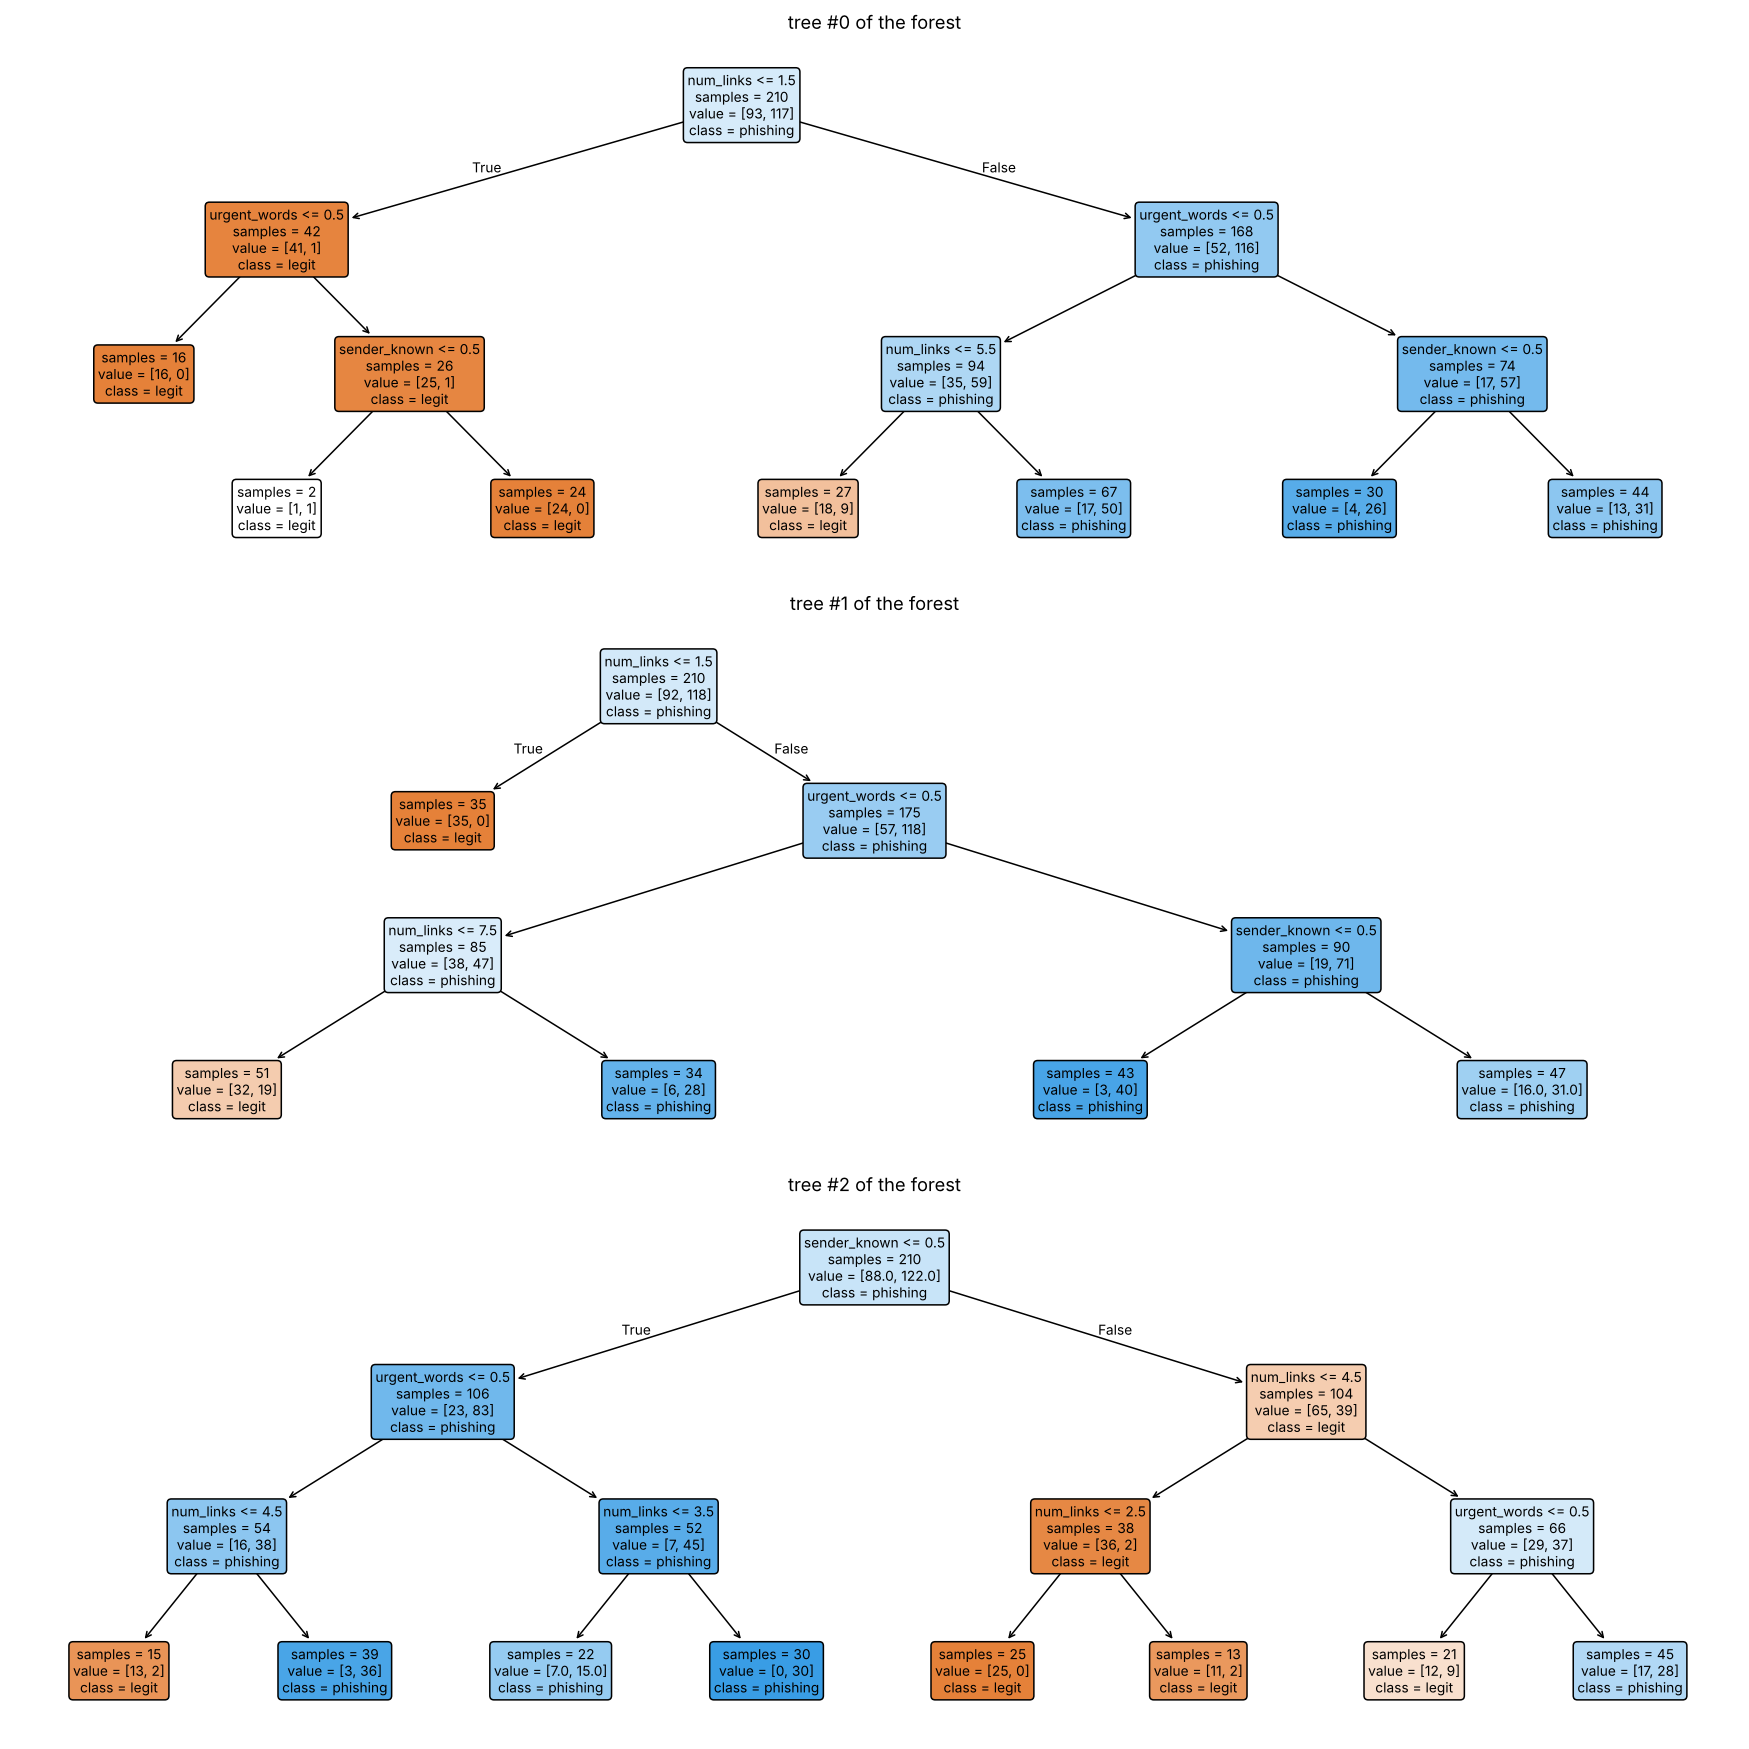

In [ ]:
rf_vis = RandomForestScratch(n_estimators=100, max_depth=3, random_state=42).fit(X_train, y_train)

fig, axes = plt.subplots(3, 1, figsize=(16, 16))
for i, ax in enumerate(axes):
    t = rf_vis.trees_[i]
    plot_tree(t, feature_names=features, class_names=[class_names[c] for c in t.classes_],
              filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
    ax.set_title(f"tree #{i} of the forest")
plt.tight_layout()
plt.show()

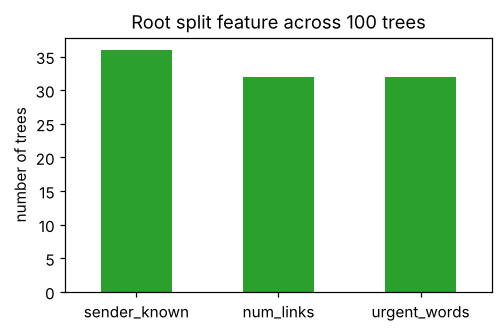

In [ ]:
# Which feature does each tree split on first? (diversity of the forest)
root_features = [features[t.tree_.feature[0]] for t in rf.trees_ if t.tree_.node_count > 1]
pd.Series(root_features).value_counts().plot.bar(color="tab:green", figsize=(5, 3),
                                                 title="Root split feature across 100 trees")
plt.ylabel("number of trees"); plt.xticks(rotation=0); plt.show()

Because `max_features="sqrt"` gives only 1 random feature per split here, the root feature differs from tree to tree. Without this randomness almost every tree would start with the strongest feature, and the trees would be highly correlated.

## 6. Comparison with `sklearn.ensemble.RandomForestClassifier`

Same hyperparameters: 100 trees, `max_features="sqrt"`, full-depth trees, bootstrap, soft voting.
The two models use **different random number generators**, so they build different trees. I do not expect identical numbers, only **statistically equivalent** behaviour.

In [ ]:
sk_rf = RandomForestClassifier(n_estimators=100, max_features="sqrt", oob_score=True, random_state=42)

t0 = time.perf_counter(); rf.fit(X_train, y_train);    t_ours = time.perf_counter() - t0
t0 = time.perf_counter(); sk_rf.fit(X_train, y_train); t_sk = time.perf_counter() - t0

comparison = pd.DataFrame({
    "test accuracy": [rf.score(X_test, y_test), sk_rf.score(X_test, y_test)],
    "OOB accuracy":  [rf.oob_score_, sk_rf.oob_score_],
    "train accuracy":[rf.score(X_train, y_train), sk_rf.score(X_train, y_train)],
    "fit time (s)":  [t_ours, t_sk],
}, index=["RandomForestScratch", "sklearn RandomForest"]).round(3)
comparison

,test accuracy,OOB accuracy,train accuracy,fit time (s)
RandomForestScratch,0.833,0.786,0.843,0.087
sklearn RandomForest,0.822,0.790,0.843,0.105


same prediction on 98.9% of test emails
correlation of P(phishing): 0.996


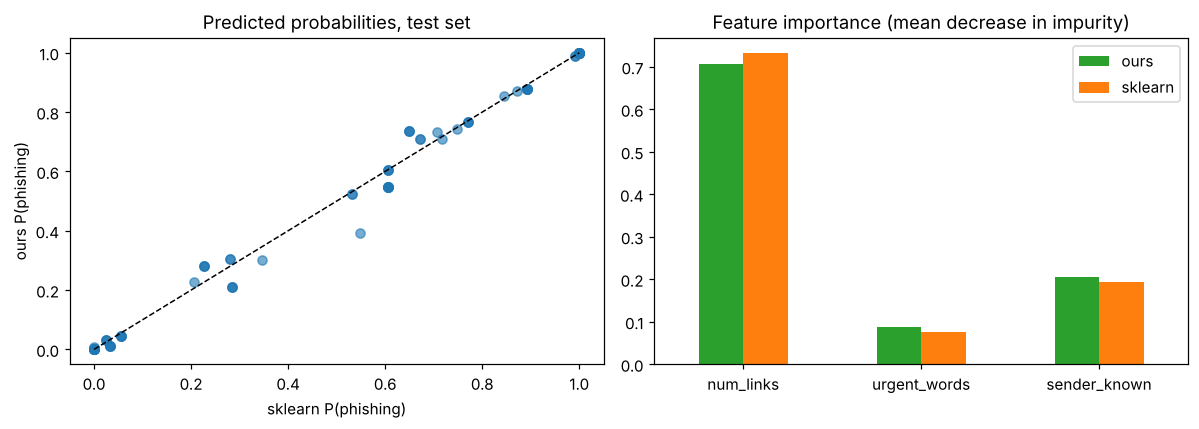

In [ ]:
p_ours = rf.predict_proba(X_test)[:, 1]      # column 1 = class +1 = phishing
p_sk = sk_rf.predict_proba(X_test)[:, 1]
agree = np.mean(rf.predict(X_test) == sk_rf.predict(X_test))
print(f"same prediction on {agree:.1%} of test emails")
print(f"correlation of P(phishing): {np.corrcoef(p_ours, p_sk)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(p_sk, p_ours, alpha=0.6)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("sklearn P(phishing)"); axes[0].set_ylabel("ours P(phishing)")
axes[0].set_title("Predicted probabilities, test set")

imp = pd.DataFrame({"ours": rf.feature_importances_, "sklearn": sk_rf.feature_importances_},
                   index=features)
imp.plot.bar(ax=axes[1], rot=0, color=["tab:green", "tab:orange"])
axes[1].set_title("Feature importance (mean decrease in impurity)")
plt.tight_layout(); plt.show()

Both forests produce almost the same probabilities and the same ranking of feature importance. That matches the generating rule: `sender_known` (weight −2) and `num_links` (0.5 per link, up to 9 links) matter most, and `urgent_words` (1.5) less.

## 7. Hyperparameter analysis

To get stable numbers I use **5-fold cross-validation** on all 300 emails. The CV helper is written by hand, and it works for our model and for sklearn because both have `fit` / `predict`.

In [ ]:
def cv_accuracy(make_model, X, y, k=5, seed=0):
    # Shuffle, split into k folds, train on k-1 folds and test on the remaining one.
    rng = np.random.default_rng(seed)
    folds = np.array_split(rng.permutation(len(X)), k)
    scores = []
    for i in range(k):
        test_idx = folds[i]
        train_idx = np.concatenate(folds[:i] + folds[i + 1:])
        model = make_model().fit(X[train_idx], y[train_idx])
        scores.append(np.mean(model.predict(X[test_idx]) == y[test_idx]))
    return np.mean(scores)

### 7.1 Number of trees `n_estimators`

In [ ]:
n_list = [1, 2, 5, 10, 20, 50, 100, 200]
res = []
for n_est in n_list:
    ours = RandomForestScratch(n_estimators=n_est, random_state=0).fit(X_train, y_train)
    sk = RandomForestClassifier(n_estimators=n_est, random_state=0,
                                oob_score=n_est >= 5).fit(X_train, y_train)
    res.append({
        "n_estimators": n_est,
        "CV ours": cv_accuracy(lambda: RandomForestScratch(n_estimators=n_est, random_state=0), X, y),
        "CV sklearn": cv_accuracy(lambda: RandomForestClassifier(n_estimators=n_est, random_state=0), X, y),
        "OOB ours": ours.oob_score_,
        "OOB sklearn": sk.oob_score_ if n_est >= 5 else np.nan,   # sklearn needs enough trees for OOB
    })
res_n = pd.DataFrame(res).set_index("n_estimators")
res_n.round(3)

/usr/local/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


/usr/local/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,CV ours,CV sklearn,OOB ours,OOB sklearn
n_estimators,,,,
1,0.763,0.757,0.746,NaN
2,0.770,0.783,0.798,NaN
5,0.760,0.790,0.742,0.748
10,0.770,0.783,0.775,0.729
20,0.790,0.790,0.776,0.771
50,0.780,0.780,0.786,0.781
100,0.787,0.777,0.776,0.781
200,0.787,0.777,0.781,0.790


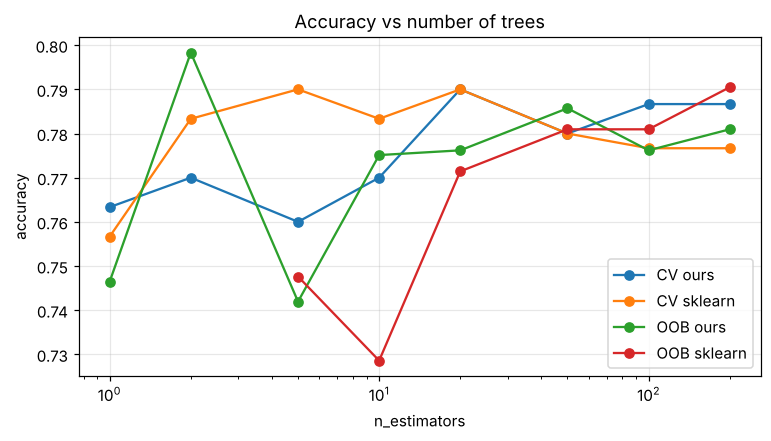

In [ ]:
ax = res_n.plot(marker="o", logx=True, figsize=(8, 4))
ax.set_ylabel("accuracy"); ax.set_title("Accuracy vs number of trees")
ax.grid(alpha=0.3); plt.show()

* Accuracy increases quickly over the first ~20 trees, then **flattens out**.
* More trees **never cause overfitting**. They only reduce variance, with diminishing returns, and cost more compute.
* With very few trees the OOB estimate is unreliable, because many rows were never out-of-bag.

### 7.2 Tree depth `max_depth`

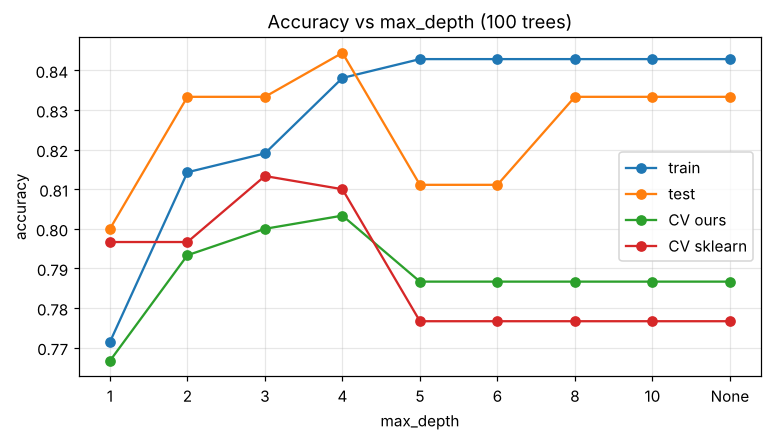

,train,test,CV ours,CV sklearn
max_depth,,,,
1,0.771,0.800,0.767,0.797
2,0.814,0.833,0.793,0.797
3,0.819,0.833,0.800,0.813
4,0.838,0.844,0.803,0.810
5,0.843,0.811,0.787,0.777
6,0.843,0.811,0.787,0.777
8,0.843,0.833,0.787,0.777
10,0.843,0.833,0.787,0.777
None,0.843,0.833,0.787,0.777


In [ ]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
res = []
for d in depths:
    m = RandomForestScratch(n_estimators=100, max_depth=d, random_state=0).fit(X_train, y_train)
    res.append({"max_depth": str(d),
                "train": m.score(X_train, y_train),
                "test": m.score(X_test, y_test),
                "CV ours": cv_accuracy(lambda: RandomForestScratch(100, max_depth=d, random_state=0), X, y),
                "CV sklearn": cv_accuracy(lambda: RandomForestClassifier(100, max_depth=d, random_state=0), X, y)})
res_d = pd.DataFrame(res).set_index("max_depth")
ax = res_d.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("accuracy"); ax.set_title("Accuracy vs max_depth (100 trees)")
ax.grid(alpha=0.3); plt.show()
res_d.round(3)

* Depth 1 **underfits**: one split cannot combine the 3 features.
* CV accuracy is best around **depth 3–4**. Deeper trees start fitting the noise (individual cells with few emails), and CV accuracy drops slightly.
* From depth 5 on nothing changes: the trees have already split all 40 possible emails apart, so extra depth has nothing left to split.
* Classic Random Forests grow full trees (`max_depth=None`) and rely on averaging to control the variance. On small, noisy data like ours, limiting the depth acts as extra regularisation and helps a little.

### 7.3 Features per split `max_features`
With 3 features I can try 1, 2 and 3. **`max_features=3` means no feature randomness**, which is plain bagging.

I also measure **tree diversity**: the average fraction of test emails on which two trees of the forest disagree.

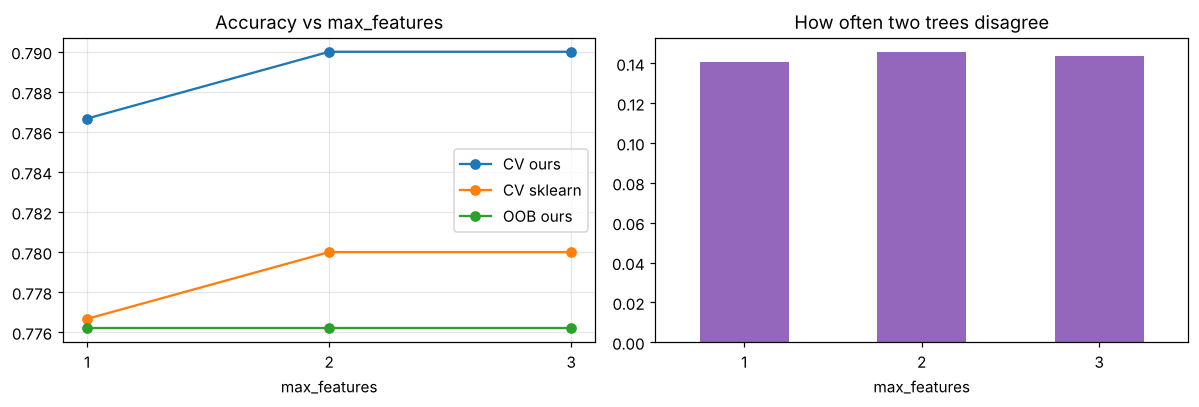

,CV ours,CV sklearn,OOB ours,tree diversity
max_features,,,,
1,0.787,0.777,0.776,0.141
2,0.790,0.780,0.776,0.145
3,0.790,0.780,0.776,0.144


In [ ]:
def tree_diversity(forest, X):
    preds = np.array([t.predict(X) for t in forest.trees_])
    T = len(preds)
    pair_disagreement = [np.mean(preds[i] != preds[j]) for i in range(T) for j in range(i + 1, T)]
    return np.mean(pair_disagreement)

res = []
for mf in [1, 2, 3]:
    m = RandomForestScratch(n_estimators=100, max_features=mf, random_state=0).fit(X_train, y_train)
    res.append({"max_features": mf,
                "CV ours": cv_accuracy(lambda: RandomForestScratch(100, max_features=mf, random_state=0), X, y),
                "CV sklearn": cv_accuracy(lambda: RandomForestClassifier(100, max_features=mf, random_state=0), X, y),
                "OOB ours": m.oob_score_,
                "tree diversity": tree_diversity(m, X_test)})
res_f = pd.DataFrame(res).set_index("max_features")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
res_f[["CV ours", "CV sklearn", "OOB ours"]].plot(marker="o", ax=axes[0], xticks=[1, 2, 3])
axes[0].set_title("Accuracy vs max_features"); axes[0].grid(alpha=0.3)
res_f["tree diversity"].plot.bar(ax=axes[1], rot=0, color="tab:purple")
axes[1].set_title("How often two trees disagree")
plt.tight_layout(); plt.show()
res_f.round(3)

* **On this dataset `max_features` barely matters.** The trees have different *structures* (the root-split chart in 5.1), but full-depth trees end up cutting the input space into the same 40 cells whatever order they split in. So their *predictions* are almost the same, and the diversity here comes mainly from the bootstrap samples.
* In general (see 8.6), fewer features per split gives more diverse trees. This is a trade-off:
  * diverse trees have errors that are *less correlated*, so averaging removes more of them (lower variance),
  * but each tree on its own is weaker (higher bias).
* The forest's error depends on **both** the strength of the individual trees and the **correlation** between them (Breiman, 2001). The best `max_features` balances the two. The common defaults are $\sqrt{p}$ for classification and $p/3$ for regression.


### 7.4 Bootstrap sample size `max_samples`

The lecture lists three Random Forest parameters: number of trees, **sample size** and size of the feature subset. Sample size is how many emails each tree draws, as a fraction of the training set. The classic choice is 100 % (n draws with replacement).

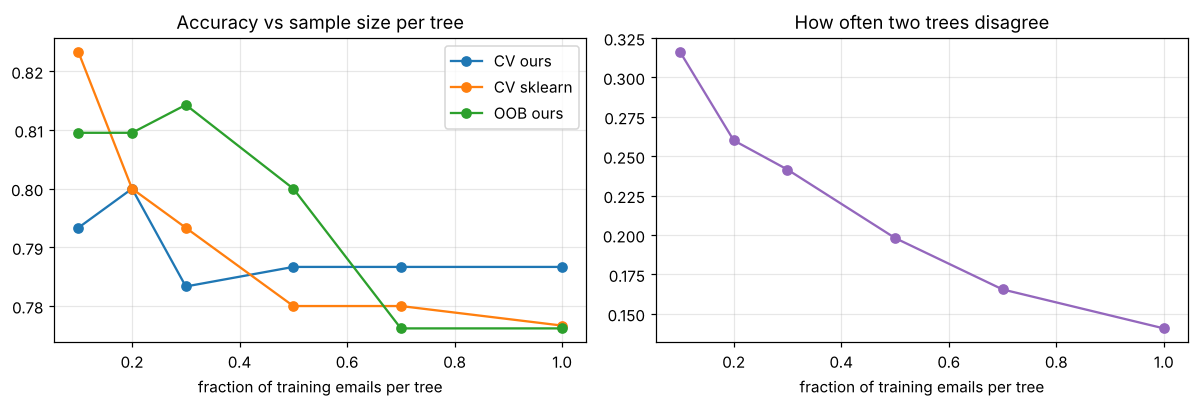

,CV ours,CV sklearn,OOB ours,tree diversity
max_samples,,,,
0.1,0.793,0.823,0.810,0.316
0.2,0.800,0.800,0.810,0.260
0.3,0.783,0.793,0.814,0.242
0.5,0.787,0.780,0.800,0.198
0.7,0.787,0.780,0.776,0.165
1.0,0.787,0.777,0.776,0.141


In [ ]:
fractions = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
res = []
for f in fractions:
    m = RandomForestScratch(100, max_samples=f, random_state=0).fit(X_train, y_train)
    res.append({"max_samples": f,
                "CV ours": cv_accuracy(lambda: RandomForestScratch(100, max_samples=f, random_state=0), X, y),
                "CV sklearn": cv_accuracy(lambda: RandomForestClassifier(100, max_samples=f, random_state=0), X, y),
                "OOB ours": m.oob_score_,
                "tree diversity": tree_diversity(m, X_test)})
res_s = pd.DataFrame(res).set_index("max_samples")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
res_s[["CV ours", "CV sklearn", "OOB ours"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Accuracy vs sample size per tree"); axes[0].set_xlabel("fraction of training emails per tree")
axes[0].grid(alpha=0.3)
res_s["tree diversity"].plot(marker="o", ax=axes[1], color="tab:purple")
axes[1].set_title("How often two trees disagree"); axes[1].set_xlabel("fraction of training emails per tree")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
res_s.round(3)

* **Smaller samples → more diverse trees** (right plot): each tree sees a different small part of the data. But each tree is also **weaker**, because it learns from fewer emails. This is the same strength vs correlation trade-off as `max_features`, controlled from the data side instead of the feature side.
* Smaller samples also make training faster and leave more out-of-bag emails per tree.
* On our noisy data, small samples (10–20 %) are **as good or slightly better** than 100 %. A tree trained on 20–40 emails cannot split into as many tiny cells, so it fits less of the label noise. That acts as regularisation, like a smaller `max_depth`, and tree diversity more than doubles.
* The classic 100 % is a safe default. Sample size is worth tuning when the data are noisy or very large (smaller samples are also much faster).

## 8. Conclusions

* I implemented a Random Forest **from scratch**: bootstrap sampling, random features per split, soft and hard voting, out-of-bag accuracy and feature importance. Only the single decision tree comes from sklearn.
* My implementation matches `sklearn.ensemble.RandomForestClassifier` within random-seed noise in accuracy, OOB accuracy, predicted probabilities and feature importances. sklearn is faster because of compiled code and parallelism.
* **Hyperparameters:**
  * `n_estimators`: more is better, but the gain flattens out after a few dozen trees. More trees do not overfit.
  * `max_depth`: depth 1 underfits, the best results here come at depth 3–4, and deeper trees fit a little noise.
  * `max_features`: controls tree diversity, the strength vs correlation trade-off. It has little effect on our 3-feature data.
  * `max_samples` (sample size): smaller samples give more diverse but weaker trees; on our noisy data 10–20 % works as well as or better than the default 100 %.
* **Honest finding:** with only 3 discrete features (40 possible emails), one tree is already a stable lookup table and the forest's gain is small. With realistic extra features (8.6), the forest beats a single tree by a wide margin.
* **Strengths:** few hyperparameters, little tuning needed, robust to noise and outliers, free validation through OOB, feature importance, easy to parallelise.
* **Limitations:** less interpretable than one tree; large models are slow at prediction time; impurity-based importance favours features with many distinct values; poor extrapolation outside the training range; sometimes beaten by gradient boosting on tabular data.
* **Applications:** spam and phishing filtering, fraud detection, credit scoring, medical diagnosis, remote sensing and land-cover classification, bioinformatics (gene selection).